In [359]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import OneHotEncoder

datacsv=pd.read_csv('C:/Users/billp/OneDrive/Documents/617_Data/German_bank.csv')
print(datacsv.head())

nominal_vars=['checking_balance', 'purpose', 'savings_balance', 'other_credit', 'housing', 'job', 'phone']
nominal = datacsv[nominal_vars]

encoder= OneHotEncoder()
encoded_nominal=encoder.fit_transform(nominal)

encoded_names=encoder.get_feature_names_out(input_features=nominal_vars)

nominal_data=pd.DataFrame(encoded_nominal.toarray(),columns=encoded_names)
nominal_data.head()




  checking_balance  months_loan_duration credit_history               purpose  \
0           < 0 DM                     6       critical  furniture/appliances   
1       1 - 200 DM                    48           good  furniture/appliances   
2          unknown                    12       critical             education   
3           < 0 DM                    42           good  furniture/appliances   
4           < 0 DM                    24           poor                   car   

   amount savings_balance employment_duration  percent_of_income  \
0    1169         unknown           > 7 years                  4   
1    5951        < 100 DM         1 - 4 years                  2   
2    2096        < 100 DM         4 - 7 years                  2   
3    7882        < 100 DM         4 - 7 years                  2   
4    4870        < 100 DM         1 - 4 years                  3   

   years_at_residence  age other_credit housing  existing_loans_count  \
0                   4   67     

,checking_balance_1 - 200 DM,checking_balance_< 0 DM,checking_balance_> 200 DM,checking_balance_unknown,purpose_business,purpose_car,purpose_car0,purpose_education,purpose_furniture/appliances,purpose_renovations,...,other_credit_store,housing_other,housing_own,housing_rent,job_management,job_skilled,job_unemployed,job_unskilled,phone_no,phone_yes
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


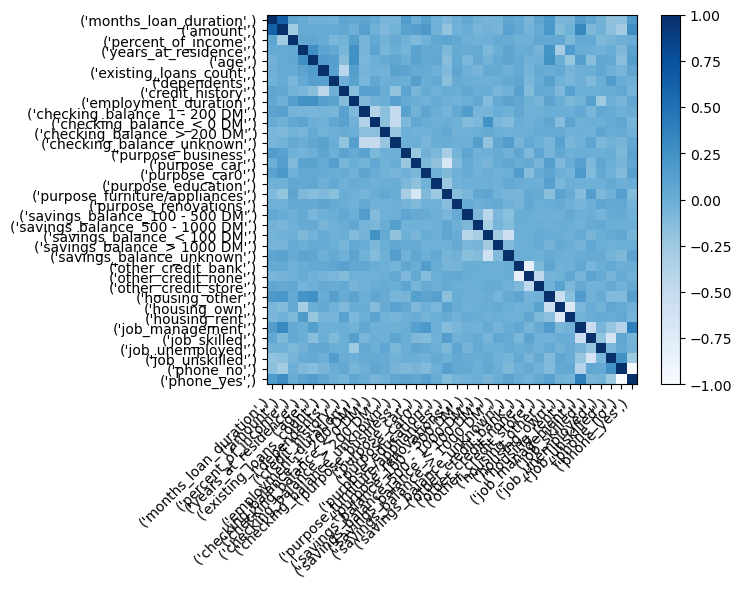

In [565]:
#correlation matrix
correlation=ind_vars.corr()


plt.imshow(correlation,cmap="Blues")
plt.colorbar()

variables=[]
for i in correlation.columns:
    variables.append(i)


plt.xticks(range(len(correlation)), variables, rotation=45, ha='right')
plt.yticks(range(len(correlation)), variables)

plt.show()

correlation.to_csv("correlation_matrix.csv")

In [421]:
ordinal_vars={
    'credit_history': ['critical', 'poor', 'good', 'very good', 'perfect'],
    'employment_duration': ['unemployed', '< 1 year', '1 - 4 years', '4 - 7 years', '> 7 years']
}

from sklearn.preprocessing import OrdinalEncoder

ordinal = datacsv[list(ordinal_vars.keys())]

ordinal_encoder=OrdinalEncoder(categories=[ordinal_vars[col] for col in ordinal.columns])

ordinal_encoded = pd.DataFrame(ordinal_encoder.fit_transform(ordinal),columns=ordinal.columns)

ordinal_encoded.head()

#merge encoded nominal and ordinal datasets

datacsv2=datacsv.drop(columns=["credit_history","employment_duration"]+list(nominal_vars))

final_data=pd.concat([datacsv2,ordinal_encoded,nominal_data],axis=1)
final_data['default']=final_data['default'].map({"yes":1,"no":0})

print(final_data.info())



final_data.to_csv("germanbank_encoded.csv",index=False)

final_data.head()




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 37 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   months_loan_duration           1000 non-null   int64  
 1   amount                         1000 non-null   int64  
 2   percent_of_income              1000 non-null   int64  
 3   years_at_residence             1000 non-null   int64  
 4   age                            1000 non-null   int64  
 5   existing_loans_count           1000 non-null   int64  
 6   dependents                     1000 non-null   int64  
 7   default                        1000 non-null   int64  
 8   credit_history                 1000 non-null   float64
 9   employment_duration            1000 non-null   float64
 10  checking_balance_1 - 200 DM    1000 non-null   float64
 11  checking_balance_< 0 DM        1000 non-null   float64
 12  checking_balance_> 200 DM      1000 non-null   fl

,months_loan_duration,amount,percent_of_income,years_at_residence,age,existing_loans_count,dependents,default,credit_history,employment_duration,...,other_credit_store,housing_other,housing_own,housing_rent,job_management,job_skilled,job_unemployed,job_unskilled,phone_no,phone_yes
0,6,1169,4,4,67,2,1,0,0.0,4.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,48,5951,2,2,22,1,1,1,2.0,2.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,12,2096,2,3,49,1,2,0,0.0,3.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
3,42,7882,2,4,45,1,2,0,2.0,3.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,24,4870,3,4,53,2,2,1,1.0,2.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


Tree Depth: 16
Number of Leaves: 204


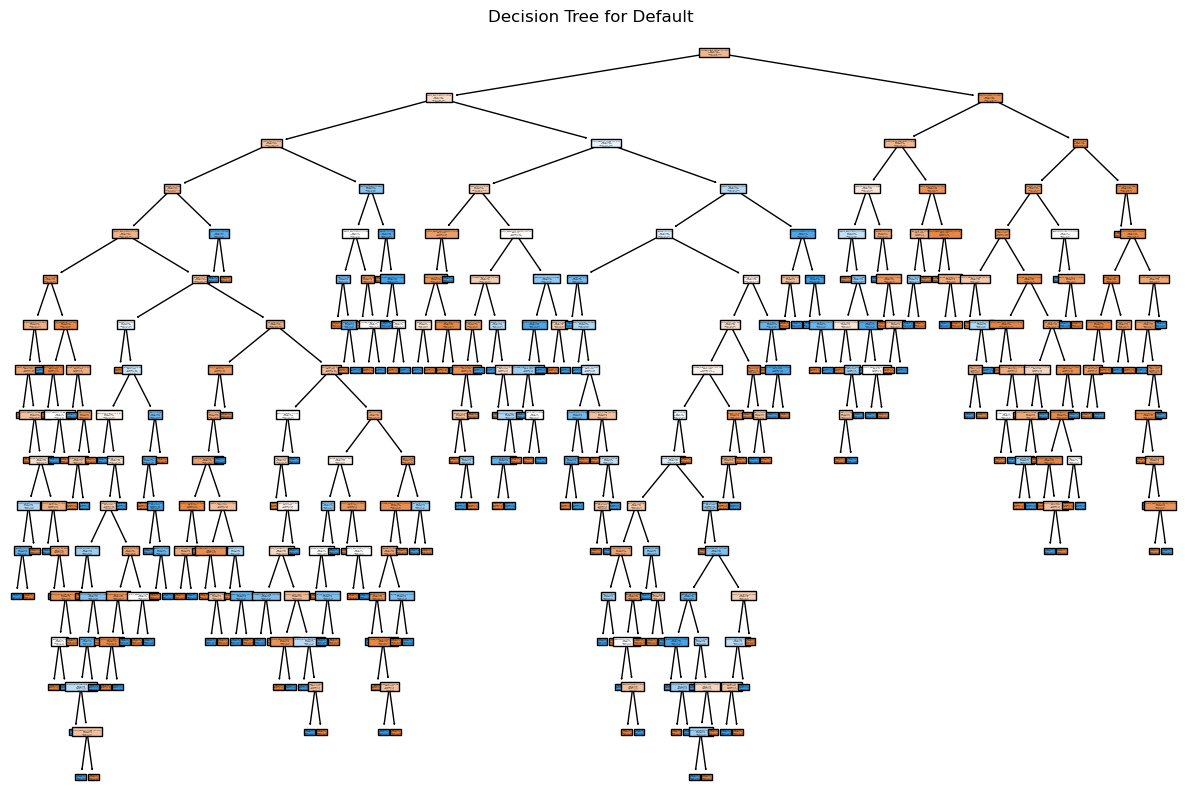

In [215]:
#classification tree
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, cross_val_score
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore',category=FutureWarning)

from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

#separate indepdendent and dependent variables
ind_vars=final_data.drop(columns="default")
dep_var=final_data["default"]


features=[ind_vars.columns.tolist()]

ind_vars=scaler.fit_transform(ind_vars)
#column names stripped, add them back
ind_vars=pd.DataFrame(ind_vars,columns=features)

dtree = DecisionTreeClassifier()
dtree=dtree.fit(ind_vars_scaled,dep_var)

print(f"Tree Depth: {dtree.get_depth()}")
print(f"Number of Leaves: {dtree.get_n_leaves()}")

plt.figure(figsize=(15, 10))
plot_tree(dtree, feature_names=ind_vars.columns, class_names=['No', 'Yes'], filled=True)
plt.title("Decision Tree for Default")
plt.savefig("treeplotfull.pdf",dpi=300)
plt.show()



In [449]:
#train test split 70/30

np.random.seed(12345)
train_indices = np.random.choice(range(len(ind_vars_scaled)), size=701, replace=False)
X_train, y_train = ind_vars.iloc[train_indices], dep_var.iloc[train_indices]
X_test, y_test = ind_vars.drop(index=train_indices), dep_var.drop(index=train_indices)

'''
#trying out the tree
tree_bank=DecisionTreeClassifier(random_state=12345)
tree_bank.fit(X_train,y_train)

'''

y_pred=tree_bank.predict(X_test)
confusion_matrix1 = pd.crosstab(y_test, y_pred, rownames=['Actual'],colnames=['Predicted'])
print(confusion_matrix1) 


Predicted    0   1
Actual            
0          148  51
1           46  54


In [353]:
print(X_train.head())
print(y_train.head())

    months_loan_duration    amount percent_of_income years_at_residence  \
144             0.008048 -0.348509          0.918477           1.046987   
833             0.256953  0.642514         -0.870183           1.046987   
270            -0.240857 -0.215947          0.918477           0.140505   
468             1.003669 -0.179794         -0.870183          -0.765977   
962            -0.489762  0.100925          0.024147          -0.765977   

          age existing_loans_count dependents credit_history  \
144 -1.103451            -0.704926   -0.42829      -1.344014   
833  0.567645            -0.704926   -0.42829       0.503428   
270 -0.311879            -0.704926   -0.42829       0.503428   
468 -0.839594             1.027079   -0.42829      -0.420293   
962 -0.575737            -0.704926   -0.42829       0.503428   

    employment_duration checking_balance_1 - 200 DM  ... other_credit_store  \
144           -1.145978                   -0.606621  ...          -0.222076   
833   

In [427]:
#cross validation for pruning

#cv_scores = cross_val_score(tree_bank, X_train, y_train, cv=5, scoring='accuracy')
#print("Cross-validation scores:", cv_scores)

#test different depths
scores = []
for depth in range(1, 10): # Test depths from 1 to 10
    tree = DecisionTreeClassifier(max_depth=depth, random_state=1)
    score = cross_val_score(tree, ind_vars,dep_var, cv=5, scoring='neg_mean_squared_er')
    cv_scores = cross_val_score(tree, ind_vars, dep_var, cv=5, scoring='accuracy')
    print(np.mean(cv_scores))
    scores.append(-score.mean())

print(scores)

0.7
0.6930000000000001
0.703
0.708
0.711
0.7100000000000001
0.725
0.708
0.721
[0.3, 0.307, 0.29700000000000004, 0.292, 0.28900000000000003, 0.29000000000000004, 0.275, 0.292, 0.279]


In [399]:
scores = []
for depth in range(1, 10): # Test depths from 1 to 10
    tree = DecisionTreeClassifier(max_depth=depth, random_state=1)
    score = cross_val_score(tree, ind_vars,dep_var, cv=5, scoring='neg_mean_squared_error')
    cv_scores = cross_val_score(tree, ind_vars, dep_var, cv=5, scoring='accuracy')
    print(np.mean(cv_scores))
    scores.append(-score.mean())


0.7
0.6930000000000001
0.703
0.708
0.711
0.7100000000000001
0.725
0.708
0.721


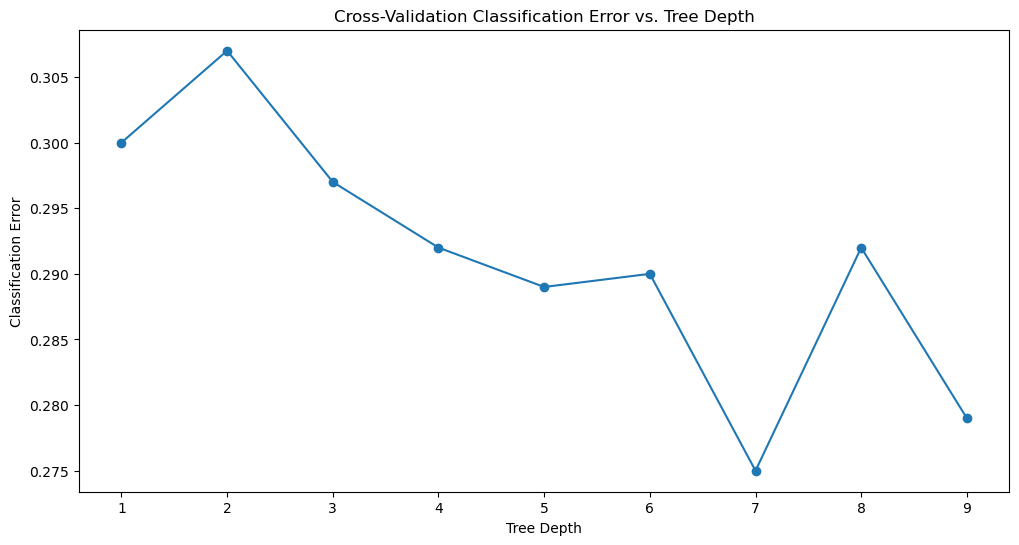

Tree Depth: 7
Number of Leaves: 30


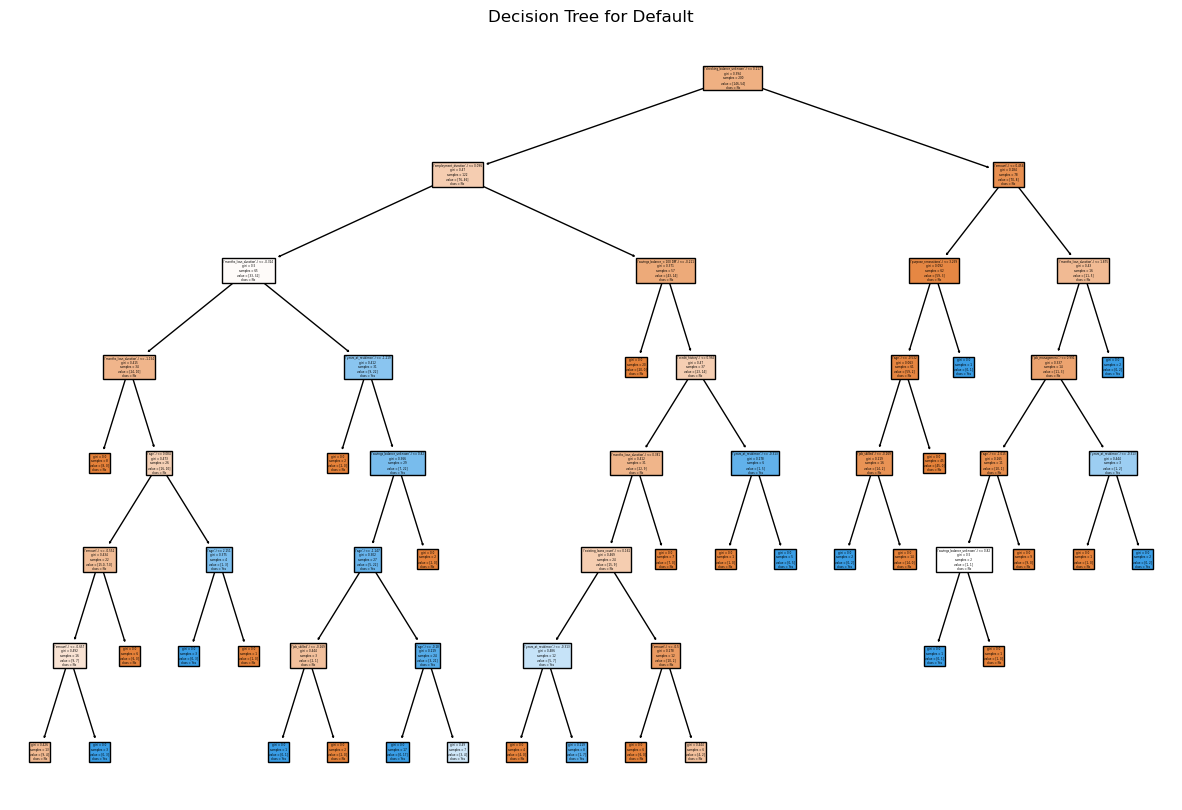

In [523]:


plt.figure(figsize=(12, 6))
plt.plot(range(1,10), scores, marker='o')
plt.title('Cross-Validation Classification Error vs. Tree Depth')
plt.xlabel('Tree Depth')
plt.ylabel('Classification Error')
plt.show()

np.random.seed(12345)
train_indices = np.random.choice(range(len(ind_vars_scaled)), size=200, replace=False)
X_train2, y_train2 = ind_vars.iloc[train_indices], dep_var.iloc[train_indices]
X_test2, y_test2 = ind_vars.drop(index=train_indices), dep_var.drop(index=train_indices)

#visualizing tree
optimal_tree=DecisionTreeClassifier(max_depth=7,random_state=12345)
optimal_tree.fit(X_train2,y_train2)
#depth of 7 is optimal


print(f"Tree Depth: {optimal_tree.get_depth()}")
print(f"Number of Leaves: {optimal_tree.get_n_leaves()}")

plt.figure(figsize=(15, 10))
plot_tree(optimal_tree, feature_names=X_test2.columns, class_names=['No', 'Yes'], filled=True)
plt.title("Decision Tree for Default")
plt.savefig("treeplotoptimal.png",dpi=500)
plt.show()






In [511]:
y_pred_pruned = optimal_tree.predict(X_test2)
confusion_matrix_pruned = pd.crosstab(y_test2, y_pred_pruned,rownames=['Actual'], colnames=['Predicted'])
print(confusion_matrix_pruned)

Predicted    0   1
Actual            
0          107  23
1           41  29


In [533]:
np.random.seed(12345)
train_indices = np.random.choice(range(len(ind_vars_scaled)), size=800, replace=False)
X_train3, y_train3 = ind_vars.iloc[train_indices], dep_var.iloc[train_indices]
X_test3, y_test3 = ind_vars.drop(index=train_indices), dep_var.drop(index=train_indices)

scores = []
for depth in range(1, 10): # Test depths from 1 to 10
    tree = DecisionTreeClassifier(max_depth=depth, random_state=1)
    score = cross_val_score(tree, X_train3,y_train3, cv=5, scoring='accuracy')
    print(np.mean(score))
    scores.append(-score.mean())

tree3=DecisionTreeClassifier(max_depth=7)
tree3.fit(X_train3,y_train3)

y_pred3=tree3.predict(X_test3)
cm3=confusion_matrix(y_pred3,y_test3)
print(cm3)



0.7125
0.7
0.72625
0.71875
0.7475
0.74875
0.7362499999999998
0.7425
0.7275
[[105  43]
 [ 25  27]]


In [521]:
#logistic regression
from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

#using scikit (doesn't support statistical inference)
logistic=LogisticRegression(random_state=12345)
logistic.fit(X_train,y_train)

print(logistic.intercept_,logistic.coef_)
y_pred_logistic=logistic.predict(X_test)
print(classification_report(y_test, y_pred_logistic))

#y_train=y_train.astype(int)

cm=confusion_matrix(y_pred_logistic,y_test)
print(cm)





[-1.20965344] [[ 4.72842461e-01  1.23222944e-01  1.87845011e-01  7.80735349e-03
   2.21262315e-02  1.06300910e-01 -6.84555588e-05  3.73094321e-01
  -3.12032463e-01  1.77540388e-01  3.20155000e-01 -6.14208744e-02
  -4.22805524e-01 -2.10072316e-03  2.20446918e-02 -4.08066493e-02
   2.09588161e-01 -1.42565109e-01  1.12072557e-01  8.61594251e-02
   4.32205933e-03  2.55076726e-01 -1.24121602e-01 -3.24592195e-01
   1.08498753e-01 -9.39608017e-02 -4.60214275e-03  1.31191253e-02
  -1.07941205e-01  1.16750396e-01 -4.97733395e-04  3.48680404e-02
  -1.76060911e-01  2.29187653e-02  6.21007829e-02 -6.21007829e-02]]
              precision    recall  f1-score   support

           0       0.75      0.87      0.81       199
           1       0.62      0.41      0.49       100

    accuracy                           0.72       299
   macro avg       0.68      0.64      0.65       299
weighted avg       0.70      0.72      0.70       299

[[174  59]
 [ 25  41]]


     const  months_loan_duration    amount  percent_of_income  \
144    1.0              0.008048 -0.348509           0.918477   
833    1.0              0.256953  0.642514          -0.870183   
270    1.0             -0.240857 -0.215947           0.918477   
468    1.0              1.003669 -0.179794          -0.870183   
962    1.0             -0.489762  0.100925           0.024147   
..     ...                   ...       ...                ...   
875    1.0             -0.821636 -0.690902           0.918477   
520    1.0              0.256953  0.792444           0.024147   
657    1.0              2.248194  2.463644           0.918477   
451    1.0             -1.236478 -0.975874           0.024147   
752    1.0             -0.738668 -0.861389          -0.870183   

     years_at_residence       age  existing_loans_count  dependents  \
144            1.046987 -1.103451             -0.704926    -0.42829   
833            1.046987  0.567645             -0.704926    -0.42829   
270   

In [661]:
#logit diagnostics


X_train_subset = X_train.iloc[:700]  # First 600 rows
y_train_subset = y_train[:700]
X_train_subset.columns= [col[0] if isinstance(col, tuple) else col for col in X_train_subset.columns]
#print(X_train_subset)
X_test.columns= [col[0] if isinstance(col, tuple) else col for col in X_test.columns]


X_train_subset = sm.add_constant(X_train_subset)
statlogit = sm.Logit(y_train_subset, X_train_subset[["months_loan_duration","percent_of_income","credit_history","checking_balance_unknown","savings_balance_unknown","purpose_furniture/appliances"]])
result = statlogit.fit()
print(result.summary())

y_pred_log = result.predict(X_test[["months_loan_duration","percent_of_income","credit_history","checking_balance_unknown","savings_balance_unknown","purpose_furniture/appliances"]])
y_pred_binary = (y_pred_log >= 0.5).astype(int)
confusion_matrix_log=confusion_matrix(y_test,y_pred_binary)

print(confusion_matrix_log)

Optimization terminated successfully.
         Current function value: 0.599279
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                default   No. Observations:                  700
Model:                          Logit   Df Residuals:                      694
Method:                           MLE   Df Model:                            5
Date:                Sat, 07 Dec 2024   Pseudo R-squ.:               -0.001688
Time:                        20:24:40   Log-Likelihood:                -419.50
converged:                       True   LL-Null:                       -418.79
Covariance Type:            nonrobust   LLR p-value:                     1.000
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
months_loan_duration             0.4783      0.093      5.127      0.000

In [543]:
#collinearity diagnostics

corrout=np.corrcoef(ind_vars,ind_vars)
print(corrout)

matrix=ind_vars.corr()
print(matrix)

[[ 1.         -0.42280346 -0.07510957 ...  0.15362041  0.04823807
  -0.24843952]
 [-0.42280346  1.         -0.18202026 ...  0.06272728  0.16872023
   0.36728487]
 [-0.07510957 -0.18202026  1.         ...  0.11761769 -0.32902511
  -0.15121839]
 ...
 [ 0.15362041  0.06272728  0.11761769 ...  1.          0.01199663
  -0.22655402]
 [ 0.04823807  0.16872023 -0.32902511 ...  0.01199663  1.
  -0.02079363]
 [-0.24843952  0.36728487 -0.15121839 ... -0.22655402 -0.02079363
   1.        ]]
                              months_loan_duration    amount  \
months_loan_duration                      1.000000  0.624984   
amount                                    0.624984  1.000000   
percent_of_income                         0.074749 -0.271316   
years_at_residence                        0.034067  0.028926   
age                                      -0.036136  0.032716   
existing_loans_count                     -0.011284  0.020795   
dependents                               -0.023834  0.017142   
cred

In [469]:
print("Unique values in y_pred:", np.unique(y_pred))
print("Unique values in y:", np.unique(dep_var))
print(len(y_test))
print(len(y_tra

Unique values in y_pred: [0 1]
Unique values in y: [0 1]
299


In [471]:
#random forest
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics

np.random.seed(12345)
forest_class=RandomForestClassifier(n_estimators=100) #2/3 of the 1001 obs
forest_class.fit(X_train,y_train)

y_pred_forest=forest_class.predict(X_test)

print("model accuracy:", metrics.accuracy_score(y_pred_forest,y_test))
cm=confusion_matrix(y_pred_forest,y_test)
print(cm)

model accuracy: 0.745819397993311
[[180  57]
 [ 19  43]]


In [489]:

#73.244% with seed 12345 and 666 leaves 


#optimizing the random forest
n_estimators_check= [10,50,100,200,300,400,500,600,666] 

best_score = 0
best_n_estimators = None

for n_estimators in n_estimators_check:
    rf = RandomForestClassifier(n_estimators=n_estimators, random_state=12345)
    cv_scores = cross_val_score(rf, ind_vars,dep_var, cv=5, scoring=('accuracy'))
    mean_score = np.mean(cv_scores)
    print(f"n_estimators: {n_estimators}, Cross-Validation Accuracy: {mean_score}")
    
    if mean_score > best_score:
        best_score = mean_score
        best_n_estimators = n_estimators

print(f"Best n_estimators: {best_n_estimators}")
print(f"Best Cross-Validation Accuracy: {best_score}")
#OLD: based on cross validation for value of n, the original n is best. However, there is little improvement after 200 estimators





n_estimators: 10, Cross-Validation Accuracy: 0.732
n_estimators: 50, Cross-Validation Accuracy: 0.748
n_estimators: 100, Cross-Validation Accuracy: 0.754
n_estimators: 200, Cross-Validation Accuracy: 0.748
n_estimators: 300, Cross-Validation Accuracy: 0.749
n_estimators: 400, Cross-Validation Accuracy: 0.7430000000000001
n_estimators: 500, Cross-Validation Accuracy: 0.744
n_estimators: 600, Cross-Validation Accuracy: 0.748
n_estimators: 666, Cross-Validation Accuracy: 0.748
Best n_estimators: 100
Best Cross-Validation Accuracy: 0.754


In [491]:
#max_depth


depths=[2,3,4,5,6]

for n in depths:
    rf = RandomForestClassifier(n_estimators=100, random_state=12345,max_depth=n)
    cv_scores = cross_val_score(rf, ind_vars, dep_var, cv=5, scoring='accuracy')
    mean_score = np.mean(cv_scores)
    print(f"max depth: {n}, Cross-Validation Accuracy: {mean_score}")
    
    if mean_score > best_score:
        best_score = mean_score
        best_n_estimators = n_estimators



max depth: 2, Cross-Validation Accuracy: 0.702
max depth: 3, Cross-Validation Accuracy: 0.707
max depth: 4, Cross-Validation Accuracy: 0.725
max depth: 5, Cross-Validation Accuracy: 0.738
max depth: 6, Cross-Validation Accuracy: 0.7379999999999999


In [493]:
print(f"Best max depth: {n}")
print(f"Best Cross-Validation Accuracy: {best_score}")


Best max depth: 6
Best Cross-Validation Accuracy: 0.754


In [497]:
max_features=["sqrt",None,"log2"]

for n in max_features:
    rf = RandomForestClassifier(n_estimators=100, random_state=12345,max_features=n)
    cv_scores = cross_val_score(rf, ind_vars, dep_var, cv=5, scoring='accuracy')
    mean_score = np.mean(cv_scores)
    print(f"max depth: {n}, Cross-Validation Accuracy: {mean_score}")
    
    if mean_score > best_score:
        best_score = mean_score
        best_n_estimators = n_estimators
print(f"Best max_features: {n}")
print(f"Best Cross-Validation Accuracy: {best_score}")

max depth: sqrt, Cross-Validation Accuracy: 0.754
max depth: None, Cross-Validation Accuracy: 0.745
max depth: log2, Cross-Validation Accuracy: 0.756
Best max_features: log2
Best Cross-Validation Accuracy: 0.7617527862208714
